In [1]:
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option('display.max_columns', None)
pd.set_option('display.width', 200)

RUTA_CSV = r'C:\Users\santa\Desktop\d_thinking\data\raw\siniestralidad_2016_2024.csv'

## 1. Carga del dataset

El archivo usa codificación Latin-1 (contiene caracteres corruptos en el origen, no reparables sin la fuente original) y separador `;`.

In [2]:
df = pd.read_csv(RUTA_CSV, encoding='latin1', sep=';')
print('Shape:', df.shape)
df.head(10)

Shape: (371003, 10)


C:\Users\santa\AppData\Local\Temp\ipykernel_15984\3652858985.py:1: DtypeWarning: Columns (0,3) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(RUTA_CSV, encoding='latin1', sep=';')


,Código,Fecha,Tipo confirmado,Dirección reporte,Tipo clase de accidente,Tipo clase de accidente.1,Tipo confirmado.1,Medio de reporte,Numero vehículos,Tipo de vehículos implicados
0,96159,1/01/2016,Solo daños,Carrera 56 Con Calle 1 A,.,.,Solo Da?os,RADIO,2,MOTOCICLETA
1,96160,1/01/2016,Negativo,Calle 72 O Con Carrera 28 H,.,.,Negativo,RADIO,.,.
2,96161,1/01/2016,Con lesionado,Carrera 94 Con Calle 4 C,ATROPELLO,ATROPELLO,Por Atropello,TELEF?NICO 127,2,MOTOCICLETA
3,96162,1/01/2016,Con lesionado,Carrera 8 A Con Calle 44,VOLCAMIENTO,VOLCAMIENTO,Por Volcamiento,RADIO,1,MOTOCICLETA
4,96163,1/01/2016,Negativo,Carrera 28 H Con Calle 72 M,.,.,Negativo,TELEF?NICO 127,.,.
5,96164,1/01/2016,Solo daños,Carrera 46 C Con Calle 36,.,.,Solo Da?os,RADIO,2,"AUTOMOVIL,MOTOCICLETA"
6,96165,1/01/2016,Negativo,CAI CORTIJO,.,.,Negativo,RADIO,2,MOTOCICLETA
7,96166,1/01/2016,Negativo,Calle 83 Con Carrera 23,.,.,Negativo,RADIO,.,.
8,96167,1/01/2016,Con lesionado,Carrera 23 Con Transversal 25,.,.,Choque con Lesionados,CAD 123,2,.
9,96168,1/01/2016,Negativo,Calle 7 N Con Carrera 44,.,.,Negativo,CAD 123,.,.


In [3]:
df.dtypes

Código                          object
Fecha                           object
Tipo confirmado                 object
Dirección reporte               object
Tipo clase de accidente         object
Tipo clase de accidente.1       object
Tipo confirmado.1               object
Medio de reporte                object
Numero vehículos                object
Tipo de vehículos implicados    object
dtype: object

## 2. Nulos y valores marcador (`.`)

El dataset usa `.` como marcador de valor vacío en varias columnas, además de nulos reales (`NaN`). Ambos deben tratarse como "sin dato".

In [4]:
resumen_nulos = []
for col in df.columns:
    resumen_nulos.append({
        'columna': col,
        'nulos': df[col].isna().sum(),
        'valor_punto': (df[col] == '.').sum(),
        'unicos': df[col].nunique()
    })
pd.DataFrame(resumen_nulos)

,columna,nulos,valor_punto,unicos
0,Código,1,0,370998
1,Fecha,1,0,3229
2,Tipo confirmado,1,2,7
3,Dirección reporte,181593,2093,65335
4,Tipo clase de accidente,1,325257,15
5,Tipo clase de accidente.1,1,325257,15
6,Tipo confirmado.1,0,23389,22
7,Medio de reporte,0,288099,18
8,Numero vehículos,0,194424,13
9,Tipo de vehículos implicados,0,222214,844


**Hallazgo:** `Dirección reporte` tiene Aprox. 49% de valores vacíos (nulos + `.`). 

## 3. Columnas duplicadas

`Tipo clase de accidente` y `Tipo clase de accidente.1` son prácticamente idénticas.

In [5]:
igualdad = (df['Tipo clase de accidente'] == df['Tipo clase de accidente.1']).mean()
print(f'Porcentaje de filas donde ambas columnas coinciden: {igualdad:.6%}')
# Se puede eliminar una de las dos en el ETL:
# df = df.drop(columns=['Tipo clase de accidente.1'])

Porcentaje de filas donde ambas columnas coinciden: 99.999730%


## 4. Fechas y evolución temporal

**Importante:** este dataset NO incluye hora, solo fecha (día). Para análisis por franja horaria se usaria el dataset de lesionados.

In [6]:
df['fecha_dt'] = pd.to_datetime(df['Fecha'], format='%d/%m/%Y', errors='coerce')
print('Rango de fechas:', df['fecha_dt'].min(), '-', df['fecha_dt'].max())
print('Fechas no parseables:', df['fecha_dt'].isna().sum())

registros_por_anio = df['fecha_dt'].dt.year.value_counts().sort_index()
registros_por_anio

Rango de fechas: 2016-01-01 00:00:00 - 2024-11-02 00:00:00
Fechas no parseables: 1


fecha_dt
2016.0    64323
2017.0    61429
2018.0    60439
2019.0    59180
2020.0    32746
2021.0    30749
2022.0    31262
2023.0    18794
2024.0    12080
Name: count, dtype: int64

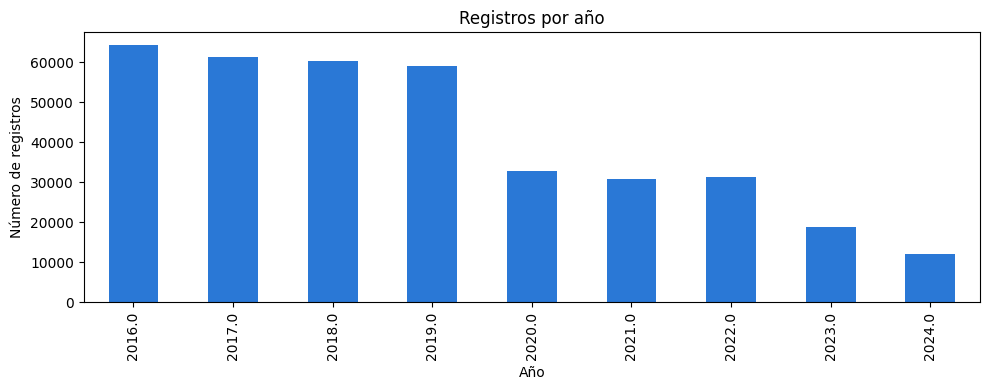

In [7]:
registros_por_anio.plot(kind='bar', figsize=(10,4), color='#2a78d6')
plt.title('Registros por año')
plt.xlabel('Año')
plt.ylabel('Número de registros')
plt.tight_layout()
plt.show()

**Nota:** hay una caída sostenida desde 2020 (de ~64,000 registros/año a ~12,000 en 2024, año incompleto hasta noviembre). Antes de interpretar esto como una tendencia real de reducción de accidentes, vale la pena investigar si hubo cambios en el proceso de captura de datos (posible efecto COVID en 2020, o cambio de sistema de reporte).

## 5. Severidad (`Tipo confirmado`)

**Hallazgo:** el 66% de los registros son `Negativo` (no se confirmó un accidente real).

In [8]:
df['Tipo confirmado'].value_counts(dropna=False)

Tipo confirmado
Negativo                   246110
Solo daños                  73828
Con lesionado               47500
Con fallecido                2907
Con fallecido (Foraneo)       453
Solo Daños                    202
.                               2
NaN                             1
Name: count, dtype: int64

In [9]:
sev_map = {
    'Negativo': 'Negativo', 'NEGATIVO': 'Negativo',
    'Solo daños': 'Solo daños', 'Solo Daños': 'Solo daños',
    'Con lesionado': 'Con lesionado',
    'Con fallecido': 'Con fallecido', 'Con fallecido (Foraneo)': 'Con fallecido'
}
df['severidad'] = df['Tipo confirmado'].map(sev_map)

tabla = df.groupby([df['fecha_dt'].dt.year, 'severidad']).size().unstack(fill_value=0)
tabla

severidad,Con fallecido,Con lesionado,Negativo,Solo daños
fecha_dt,,,,
2016.0,362,8215,47810,7936
2017.0,394,6985,44413,9637
2018.0,451,6475,37085,16428
2019.0,392,5974,35672,17142
2020.0,392,4167,18749,9438
2021.0,374,4175,19099,7101
2022.0,384,4131,21283,5464
2023.0,387,3963,13878,566
2024.0,224,3415,8121,318


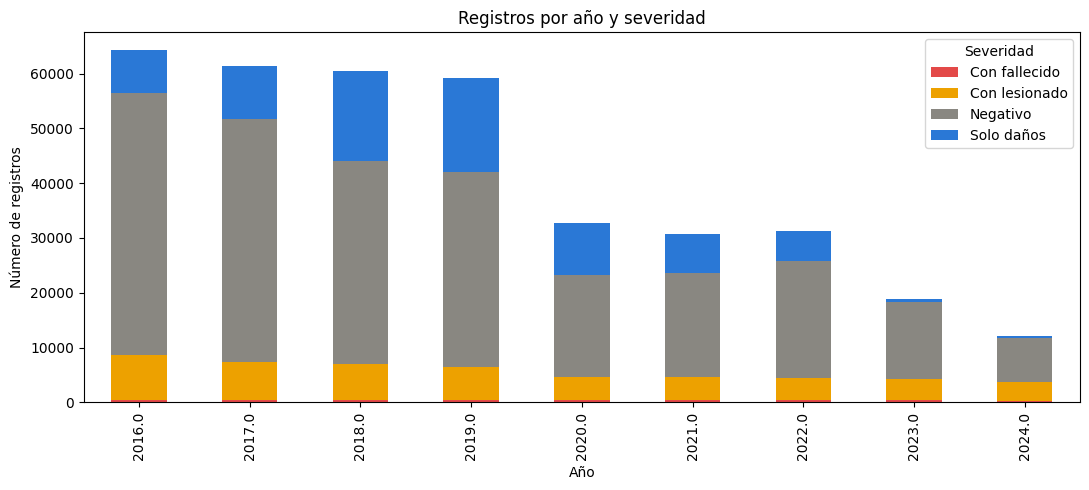

In [10]:
tabla.plot(kind='bar', stacked=True, figsize=(11,5),
           color=['#e34948','#eda100','#898781','#2a78d6'])
plt.title('Registros por año y severidad')
plt.xlabel('Año')
plt.ylabel('Número de registros')
plt.legend(title='Severidad')
plt.tight_layout()
plt.show()

## 6. Tipo de accidente y medio de reporte

In [11]:
df.loc[df['Tipo clase de accidente'] != '.', 'Tipo clase de accidente'].value_counts()

Tipo clase de accidente
Choque               20548
CHOQUE               12084
ATROPELLO             5618
NO APLICA             2819
VOLCAMIENTO           1350
CAIDA DE OCUPANTE     1105
Atropello              993
Volcamiento            588
Ca?da Ocupante         371
OTRO                   118
Otro                    82
NOAPLICA                66
Da?os                    2
Incendio                 1
Name: count, dtype: int64

In [12]:
df['Medio de reporte'].value_counts().head(10)

Medio de reporte
.                 288099
TELEF?NICO 127     27985
CAD 123            21229
RADIO              20039
CAT 127             5836
AGENTE RADIO        4974
AGENTE CAD 123      2182
REDES SOCIALES       457
TELEF?NICO127         78
CAD123                54
Name: count, dtype: int64

## 7. Vehículos implicados

Campo de texto libre separado por comas.

In [13]:
df['Tipo de vehículos implicados'].value_counts().head(15)

Tipo de vehículos implicados
.                                  222214
AUTOMOVIL,AUTOMOVIL                 38832
AUTOMOVIL,MOTOCICLETA               34436
MOTOCICLETA                         13501
AUTOMOVIL                            9612
MOTOCICLETA,MOTOCICLETA              7865
AUTOMOVIL,CAMIONETA                  4942
AUTOMOVIL,CAMION                     3867
CAMIONETA,MOTOCICLETA                2845
AUTOMOVIL,AUTOMOVIL,AUTOMOVIL        2121
AUTOMOVIL,BUSETA                     1892
AUTOMOVIL,BUS                        1292
AUTOMOVIL,"BUS PADRON"               1218
AUTOMOVIL,AUTOMOVIL,MOTOCICLETA      1187
AUTOMOVIL,VOLQUETA                   1166
Name: count, dtype: int64

## 8. Duplicados

In [14]:
print('Filas duplicadas exactas:', df.duplicated().sum())
print('Códigos duplicados:', df['Código'].duplicated().sum())

Filas duplicadas exactas: 4
Códigos duplicados: 4


## 9. Resumen de hallazgos

- **371,003 filas**: periodo 2016 nov 2024 (2024 incompleto).
- **No hay coordenadas ni comuna**: solo direcciones en texto libre (`Dirección reporte`), con ~49% de valores vacíos.
- **No hay hora del día**
- **66% de registros son "Negativo"** (no confirmados como accidente real).
- Fallecidos: Aproximadamente 3.360 en el periodo completo.
- Columna `Tipo clase de accidente.1` es prácticamente un duplicado de 'Tipo clase de accidente'.
- Caída de volumen de registros desde 2020.
- Varios campos de texto tienen caracteres corruptos en el archivo fuente (ej. `Ca?da` en vez de `Caída`) mapeable manualmente para los casos conocidos.